# Kaggle Image Classification Project - Phase / Notebook

* **Dataset**: 8-Class Image Classification Challenge
* **Target Variable**: Class Label (8 target classes)
* **Author**: 24245408/ Syed Hasan Ali

## Work Plan: Tick when stage-complete

- [x] Task 1: Dataset Exploration and Understanding
- [x] Task 2: Data Preprocessing and Pipeline Preparation
- [x] Task 3: Model Selection and Architecture Development
- [x] Task 4: Training Strategy and Overfitting/Underfitting Management
- [x] Task 5: Model Evaluation and Kaggle Submission
- [x] Task 6: Results Analysis and Improvement Strategies

## How to run this notebook

**Requirements:** Python 3 with PyTorch, torchvision, scikit-learn, pandas, NumPy, matplotlib, seaborn and Pillow (all preinstalled on Kaggle).

**On Kaggle (recommended, uses a GPU):**
1. Create a new notebook and use **File -> Import Notebook** to load this file.
2. **Settings -> Accelerator -> GPU T4**.
3. **Settings -> Turn on internet.** This competition's data cannot be attached to Kaggle notebooks, so the setup cell downloads it from the project's GitHub repository (https://github.com/Hzn-cyber/ENEL711-Kaggle-Comp).
4. **Run All** (about 55 minutes). The model weights and `submission.csv` are saved to `/kaggle/working`.

**Locally:** place the competition data in `./data` (`train/train/`, `test/test/`, `train_labels.csv`, `sample_submission.csv`) and run all cells. Without a GPU, training is very slow (several hours).

**Reproducibility:** the random seed is fixed at 42. Results on a GPU can still vary slightly between runs (see Task 4).

In [8]:
# --- SETUP: Libraries & Random Seeds ---
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split


# Set random seed for reproducibility
RANDOM_SEED = 42

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything()

# Paths setup: Kaggle notebook or local copy of the data
if os.path.exists("/kaggle/input"):
    # Kaggle notebooks can't attach this competition's data, so download it from the project's GitHub repo
    if not os.path.exists("/tmp/repo"):
        os.system("git clone --depth 1 https://github.com/Hzn-cyber/ENEL711-Kaggle-Comp.git /tmp/repo")
    DATA_DIR = "/tmp/repo/data"
    WORKING_DIR = "/kaggle/working"
else:
    DATA_DIR = "./data"
    WORKING_DIR = "./working"
TRAIN_IMG_DIR = os.path.join(DATA_DIR, "train", "train")
TEST_IMG_DIR = os.path.join(DATA_DIR, "test", "test")
os.makedirs(WORKING_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


# Task 1: Dataset Exploration and Understanding

Each image is a close-up of one facial feature of a cat or a dog. The model has to predict which of **8 classes** it shows: the species (Cat / Dog) combined with the part (Eye / Face / Mouth / Nose).

| Item | Dataset Specification / Finding |
| :--- | :--- |
| **Problem** | Multi-class image classification, 8 classes, scored by accuracy. |
| **Prediction objective** | Predict the class of each unlabelled test image. |
| **Source** | Kaggle competition dataset. Local directory: `./data/` |
| **Data structure** | `train/train/` has 63,660 labelled JPGs in one folder; labels are in `train_labels.csv` (`image_id`, `class`). `test/test/` has 29,443 unlabelled JPGs. `sample_submission.csv` shows the output format. |
| **Target classes** | CatEye, CatFace, CatMouth, CatNose, DogEye, DogFace, DogMouth, DogNose |

In [9]:
# --- 1.1 Structure of the training and test data ---
train_df = pd.read_csv(os.path.join(DATA_DIR, "train_labels.csv"), dtype={"image_id": str})
sample_sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"), dtype={"image_id": str})
train_df["filename"] = train_df["image_id"] + ".jpg"

print("train_labels.csv:", train_df.shape)
print("Training images: ", len(os.listdir(TRAIN_IMG_DIR)))
print("Test images:     ", len(os.listdir(TEST_IMG_DIR)))
print("Missing labels:  ", train_df["class"].isna().sum())
print(train_df.head())
print(sample_sub.head())

train_labels.csv: (63660, 3)
Training images:  63660
Test images:      29443
Missing labels:   0
  image_id     class   filename
0    00001    DogEye  00001.jpg
1    00002  DogMouth  00002.jpg
2    00003   DogFace  00003.jpg
3    00004   DogNose  00004.jpg
4    00005   DogNose  00005.jpg
  image_id     class
0        1    DogEye
1        2   CatNose
2        3   CatNose
3        4   DogFace
4        5  DogMouth


class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogNose      5790
DogMouth     5790
DogFace      5790
Name: count, dtype: int64

Largest / smallest class: 2.4x


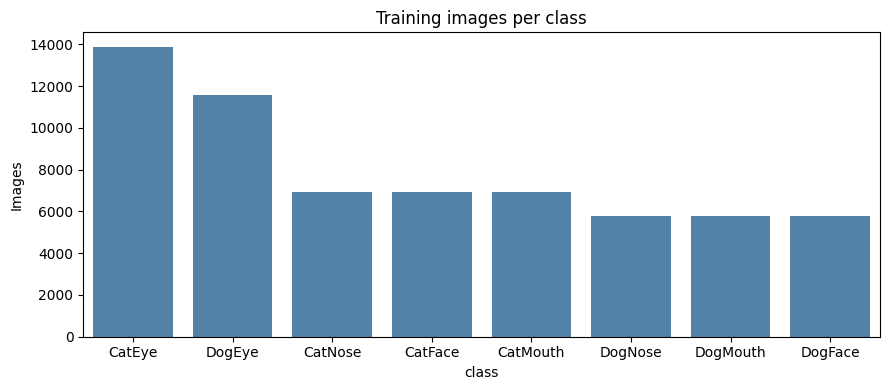

In [10]:
# --- 1.2 Number of images in each class ---
class_counts = train_df["class"].value_counts()
print(class_counts)
print(f"\nLargest / smallest class: {class_counts.max() / class_counts.min():.1f}x")

plt.figure(figsize=(9, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.title("Training images per class")
plt.ylabel("Images")
plt.tight_layout()
plt.show()

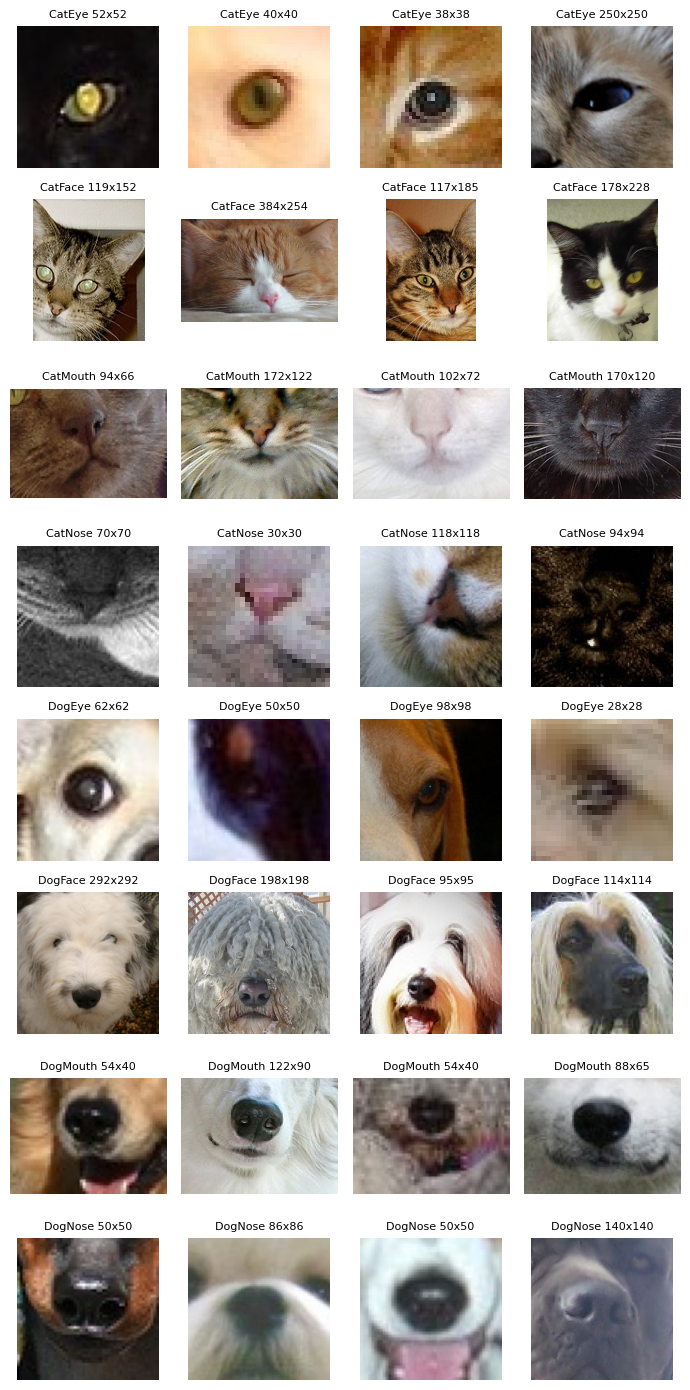

In [11]:
# --- 1.3 Sample images from each class ---
CLASS_NAMES = sorted(train_df["class"].unique())

fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(7, 14))
for row, c in enumerate(CLASS_NAMES):
    samples = train_df[train_df["class"] == c].sample(4, random_state=RANDOM_SEED)
    for col, filename in enumerate(samples["filename"]):
        img = Image.open(os.path.join(TRAIN_IMG_DIR, filename))
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{c} {img.width}x{img.height}", fontsize=8)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [12]:
# --- 1.4 Data quality: image sizes, shapes and broken files (checked on 3,000 random images each) ---
def image_info(folder, filenames):
    rows = []
    for f in filenames:
        try:
            with Image.open(os.path.join(folder, f)) as img:
                img.load()
                rows.append((f, img.width, img.height, True))
        except Exception:
            rows.append((f, None, None, False))
    return pd.DataFrame(rows, columns=["filename", "width", "height", "readable"])

train_info = image_info(TRAIN_IMG_DIR, train_df["filename"].sample(3000, random_state=RANDOM_SEED))
test_info = image_info(TEST_IMG_DIR, pd.Series(os.listdir(TEST_IMG_DIR)).sample(3000, random_state=RANDOM_SEED))
for info in (train_info, test_info):
    info["square"] = info["width"] == info["height"]

print("Broken images:", (~train_info["readable"]).sum() + (~test_info["readable"]).sum())
print(train_info[["width", "height"]].describe().round(0))

train_info = train_info.merge(train_df[["filename", "class"]], on="filename")
print("\n% of square images per class (train):")
print((train_info.groupby("class")["square"].mean() * 100).round(0))
print(f"\nSquare images overall -> train: {train_info['square'].mean():.0%}, test: {test_info['square'].mean():.0%}")

Broken images: 0
        width  height
count  3000.0  3000.0
mean    114.0   110.0
std      90.0    94.0
min      10.0    10.0
25%      54.0    50.0
50%      86.0    80.0
75%     144.0   132.0
max     829.0   958.0

% of square images per class (train):
class
CatEye      100.0
CatFace       1.0
CatMouth      0.0
CatNose      99.0
DogEye      100.0
DogFace      57.0
DogMouth      0.0
DogNose     100.0
Name: square, dtype: float64

Square images overall -> train: 64%, test: 33%


### Inspection findings

| Topic | Finding |
| :--- | :--- |
| Structure | Every training image has a label and there are no missing values. All files are readable JPGs. |
| Class balance | **Imbalanced.** CatEye has 2.4x as many images as DogFace, DogMouth or DogNose, because every animal gives two eye crops. A model that always guessed CatEye would get about 22%, so that is the baseline to beat. The split in Task 2 is stratified to keep these proportions. |
| Image sizes | Very varied: from under 10 px to over 1,000 px wide, with a median of about 80 px. All images need resizing to one size. |
| Image shape | In training, eyes and noses are almost always square and mouths are always wide. In the test set only about a third of images are square, so test crops come in more varied shapes. The model should not learn "square = eye or nose", so training uses random crops with varied shapes (Task 2). |
| Unclear boundaries | Mouth crops often include the nose, and tiny crops are very blurry. Mouth vs Nose and Cat vs Dog for the same part are likely to be the hardest pairs. |

**How the data will be used:** `train_labels.csv` is split 80/20 into training and validation sets. The model learns from the training set only; the validation set is used to monitor training and to measure performance. The test images are only used at the end to create the Kaggle submission file (`image_id,class`) in the order of `sample_submission.csv`.

# Task 2: Data Preprocessing and Pipeline Preparation

In [13]:
# --- 2.1 Label encoding and stratified train/validation split ---
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}
train_df["label"] = train_df["class"].map(CLASS_TO_IDX)
print(CLASS_TO_IDX)

train_split, val_split = train_test_split(
    train_df, test_size=0.2, stratify=train_df["label"], random_state=RANDOM_SEED)
print("Train:", len(train_split), "| Validation:", len(val_split))
print(pd.DataFrame({
    "train %": train_split["class"].value_counts(normalize=True) * 100,
    "val %": val_split["class"].value_counts(normalize=True) * 100,
}).round(1))

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Train: 50928 | Validation: 12732
          train %  val %
class                   
CatEye       21.8   21.8
CatFace      10.9   10.9
CatMouth     10.9   10.9
CatNose      10.9   10.9
DogEye       18.2   18.2
DogFace       9.1    9.1
DogMouth      9.1    9.1
DogNose       9.1    9.1


In [14]:
# --- 2.2 Resizing, normalisation and augmentation ---
IMG_SIZE = 128
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet statistics, expected by pretrained ResNet18

# Training images get random augmentation every epoch
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.75, 1.33)),  # random zoom and shape
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),             # pixels 0-255 -> 0-1
    transforms.Normalize(MEAN, STD),
])

# Validation and test images all get the same fixed steps (no randomness)
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [15]:
# --- 2.3 Dataset and DataLoaders ---
class FacialFeatureDataset(Dataset):
    def __init__(self, df, folder, transform):
        self.df = df.reset_index(drop=True)
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(self.folder, row["filename"])).convert("RGB")
        target = row["label"] if "label" in row else row["image_id"]  # test images have no label
        return self.transform(img), target


# Test images in the same order as sample_submission.csv (its IDs have no leading zeros)
test_df = sample_sub[["image_id"]].copy()
test_df["filename"] = test_df["image_id"].str.zfill(5) + ".jpg"

BATCH_SIZE = 64
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
train_loader = DataLoader(FacialFeatureDataset(train_split, TRAIN_IMG_DIR, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(FacialFeatureDataset(val_split, TRAIN_IMG_DIR, eval_transform),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(FacialFeatureDataset(test_df, TEST_IMG_DIR, eval_transform),
                         batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

images, labels = next(iter(train_loader))
print("Batch of images:", tuple(images.shape), "| labels:", labels[:8].tolist())

Batch of images: (64, 3, 128, 128) | labels: [3, 0, 3, 6, 4, 2, 1, 1]


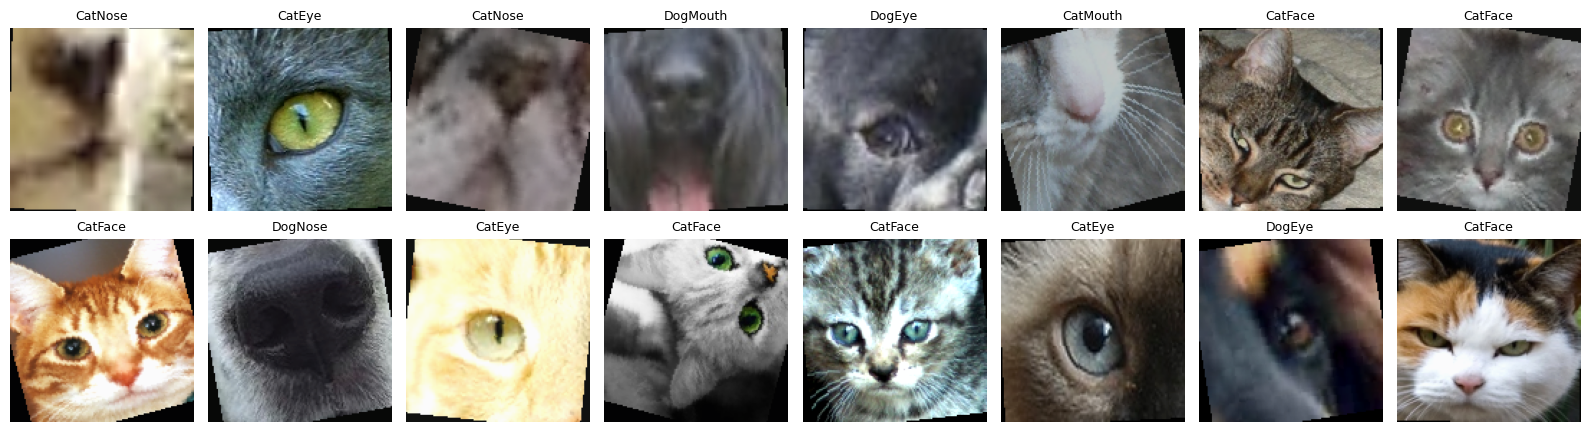

In [16]:
# --- 2.4 Check: one augmented training batch ---
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, img, label in zip(axes.flatten(), images, labels):
    img = img.permute(1, 2, 0).numpy() * STD + MEAN  # undo normalisation for display
    ax.imshow(img.clip(0, 1))
    ax.set_title(IDX_TO_CLASS[int(label)], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Preprocessing choices

| Step | Choice | Why |
| :--- | :--- | :--- |
| Resize | 128 x 128 | Images are small (median ~80 px), so 128 keeps the detail while staying fast to train. |
| Normalise | `ToTensor()` (0-1), then ImageNet mean/std | Scaled inputs train faster (lec09); the pretrained ResNet18 expects ImageNet statistics. |
| Labels | Class names mapped to 0-7 | Cross-entropy loss in PyTorch takes integer class labels. |
| Split | Stratified 80/20, `random_state=42` | Keeps the same class proportions in both sets despite the imbalance (as in LAB4). |
| Augmentation | Random crop with varied zoom and shape, flip, rotation ±15°, brightness/contrast | Gives more variety and reduces overfitting (lec11). The varied crop shapes stop the model relying on image shape, which differs in the test set. Training images only. |
| Loaders | `Dataset` + `DataLoader`, batch size 64 | Loads images in mini-batches instead of all at once; training data shuffled, test kept in submission order. |

**Avoiding data leakage:** the split is made before any training, validation and test images use the same fixed `eval_transform` with no augmentation, the normalisation values are fixed constants, and the test images are only used for the final predictions.

# Task 3: Model Selection and Pipeline Development

Two models are built so they can be compared in Task 6:
* **Model A - simple CNN**, trained from scratch, following the "typical CNN" structure from lec11 (convolution -> ReLU -> pooling blocks, then flatten -> fully connected -> softmax).
* **Model B - ResNet18 with transfer learning**: a CNN pretrained on ImageNet, with its last layer replaced by a new 8-class layer and then fine-tuned on this dataset (lec11, transfer learning).

In [17]:
# --- 3.1 Model A: simple CNN ---
import time
import torch.nn as nn
from torchvision import models

NUM_CLASSES = len(CLASS_NAMES)

def conv_block(c_in, c_out):
    """Convolution -> batch normalisation -> ReLU -> 2x2 max pooling (halves height and width)."""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        # 128x128 -> 64 -> 32 -> 16 -> 8, with more filters in each deeper block
        self.features = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),                      # 128 feature maps of 8x8 -> 8,192 values
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.5),                   # randomly drops half the neurons while training (lec11)
            nn.Linear(256, num_classes),       # one output per class
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print(SimpleCNN())
print("Trainable parameters:", sum(p.numel() for p in SimpleCNN().parameters()))

SimpleCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 

In [18]:
# --- 3.2 Model B: pretrained ResNet18 (transfer learning) ---
def build_resnet18(num_classes=NUM_CLASSES):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)  # weights learned on ImageNet
    model.fc = nn.Linear(model.fc.in_features, num_classes)                 # replace 1000-class layer with 8 classes
    return model

print("ResNet18 final layer:", build_resnet18().fc)
print("Trainable parameters:", sum(p.numel() for p in build_resnet18().parameters()))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s] 


ResNet18 final layer: Linear(in_features=512, out_features=8, bias=True)
Trainable parameters: 11180616


In [19]:
# --- 3.3 Training pipeline ---
def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over the data: trains the model if an optimizer is given, otherwise only evaluates it."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)              # forward pass
            loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()                  # backpropagation
                optimizer.step()                 # update the weights
            total_loss += loss.item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count


def train_model(model, name, epochs, lr, use_scheduler=False, patience=None):
    """Train for a number of epochs, record the learning curves and keep the best model on validation accuracy.

    Optional (used in Task 4): a learning-rate scheduler that halves the learning rate when validation loss
    stops improving, and early stopping after `patience` epochs without a lower validation loss.
    """
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=1) if use_scheduler else None
    best_path = os.path.join(WORKING_DIR, f"{name}_best.pt")
    history, best_acc, best_loss, epochs_without_improvement = [], 0.0, float("inf"), 0

    for epoch in range(1, epochs + 1):
        start = time.time()
        current_lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc, "lr": current_lr})
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), best_path)
        print(f"{name} epoch {epoch}/{epochs} | train loss {train_loss:.3f}, acc {train_acc:.3f}"
              f" | val loss {val_loss:.3f}, acc {val_acc:.3f} | lr {current_lr:.0e} | {time.time() - start:.0f}s")

        if scheduler:
            scheduler.step(val_loss)
        if val_loss < best_loss:
            best_loss, epochs_without_improvement = val_loss, 0
        else:
            epochs_without_improvement += 1
        if patience and epochs_without_improvement >= patience:
            print(f"Early stopping: validation loss has not improved for {patience} epochs")
            break

    model.load_state_dict(torch.load(best_path))
    print(f"Best validation accuracy for {name}: {best_acc:.4f}")
    return model, pd.DataFrame(history)

In [20]:
# --- 3.4 Predictions for the Kaggle test set ---
def predict(model, loader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for images, _ in loader:
            predictions.extend(model(images.to(DEVICE)).argmax(1).cpu().tolist())
    return predictions

def make_submission(model, filename="submission.csv"):
    submission = pd.DataFrame({
        "image_id": test_df["image_id"],
        "class": [IDX_TO_CLASS[p] for p in predict(model, test_loader)],
    })
    submission.to_csv(os.path.join(WORKING_DIR, filename), index=False)
    return submission

### Model architecture

| | Model A: simple CNN | Model B: ResNet18 |
| :--- | :--- | :--- |
| Input | 128 x 128 x 3 (RGB) | 128 x 128 x 3 (RGB) |
| Main components | 4 blocks of 3x3 convolution -> batch norm -> ReLU -> 2x2 max pooling (32, 64, 128, 128 filters), then flatten -> fully connected (256) -> dropout 0.5 | 18-layer CNN with residual (skip) connections, pretrained on 1.2 million ImageNet images |
| Output layer | Fully connected, 8 outputs | New fully connected layer, 8 outputs |
| Output activation | Softmax (applied inside `CrossEntropyLoss`; the highest score is the predicted class) | Softmax (same) |
| Why | A from-scratch baseline that shows what a basic CNN can learn on its own | Pretrained filters already detect edges, textures and shapes, so it needs less data and training to reach high accuracy |

### Training settings

| Setting | Model A | Model B | Why |
| :--- | :--- | :--- | :--- |
| Loss | Cross-entropy | Cross-entropy | Standard loss for multi-class classification (lec09/11). |
| Optimiser | Adam | Adam | Adapts the step size for each weight, so it works well without much tuning. |
| Learning rate | 0.001 | 0.0001 | Model A starts from random weights. Model B uses a smaller rate so it does not overwrite the useful pretrained weights. |
| Batch size | 64 | 64 | Fits comfortably in GPU memory and gives stable updates. |
| Epochs | 10 | 10 | Enough to see the learning curves level off; the best epoch on validation accuracy is kept. |

# Task 4: Training Strategy and Overfitting/Underfitting Management

In [21]:
# --- 4.1 Train Model A: simple CNN ---
seed_everything()
cnn_model, cnn_history = train_model(SimpleCNN(), "simple_cnn", epochs=10, lr=1e-3)

simple_cnn epoch 1/10 | train loss 1.108, acc 0.576 | val loss 0.357, acc 0.864 | lr 1e-03 | 76s
simple_cnn epoch 2/10 | train loss 0.647, acc 0.750 | val loss 0.254, acc 0.913 | lr 1e-03 | 75s
simple_cnn epoch 3/10 | train loss 0.526, acc 0.804 | val loss 0.180, acc 0.938 | lr 1e-03 | 75s
simple_cnn epoch 4/10 | train loss 0.467, acc 0.821 | val loss 0.149, acc 0.952 | lr 1e-03 | 75s
simple_cnn epoch 5/10 | train loss 0.436, acc 0.835 | val loss 0.157, acc 0.943 | lr 1e-03 | 74s
simple_cnn epoch 6/10 | train loss 0.402, acc 0.848 | val loss 0.124, acc 0.958 | lr 1e-03 | 74s
simple_cnn epoch 7/10 | train loss 0.383, acc 0.853 | val loss 0.125, acc 0.957 | lr 1e-03 | 75s
simple_cnn epoch 8/10 | train loss 0.371, acc 0.860 | val loss 0.108, acc 0.966 | lr 1e-03 | 75s
simple_cnn epoch 9/10 | train loss 0.346, acc 0.870 | val loss 0.116, acc 0.960 | lr 1e-03 | 75s
simple_cnn epoch 10/10 | train loss 0.324, acc 0.878 | val loss 0.119, acc 0.958 | lr 1e-03 | 75s
Best validation accuracy for 

In [22]:
# --- 4.2 Train Model B: ResNet18 ---
seed_everything()
resnet_model, resnet_history = train_model(build_resnet18(), "resnet18", epochs=10, lr=1e-4)

resnet18 epoch 1/10 | train loss 0.171, acc 0.938 | val loss 0.086, acc 0.968 | lr 1e-04 | 77s
resnet18 epoch 2/10 | train loss 0.083, acc 0.969 | val loss 0.072, acc 0.973 | lr 1e-04 | 77s
resnet18 epoch 3/10 | train loss 0.066, acc 0.976 | val loss 0.049, acc 0.981 | lr 1e-04 | 76s
resnet18 epoch 4/10 | train loss 0.059, acc 0.978 | val loss 0.058, acc 0.977 | lr 1e-04 | 76s
resnet18 epoch 5/10 | train loss 0.055, acc 0.980 | val loss 0.070, acc 0.975 | lr 1e-04 | 76s
resnet18 epoch 6/10 | train loss 0.051, acc 0.982 | val loss 0.035, acc 0.987 | lr 1e-04 | 77s
resnet18 epoch 7/10 | train loss 0.047, acc 0.983 | val loss 0.032, acc 0.989 | lr 1e-04 | 77s
resnet18 epoch 8/10 | train loss 0.045, acc 0.983 | val loss 0.041, acc 0.986 | lr 1e-04 | 76s
resnet18 epoch 9/10 | train loss 0.043, acc 0.984 | val loss 0.049, acc 0.981 | lr 1e-04 | 77s
resnet18 epoch 10/10 | train loss 0.040, acc 0.985 | val loss 0.046, acc 0.984 | lr 1e-04 | 76s
Best validation accuracy for resnet18: 0.9888


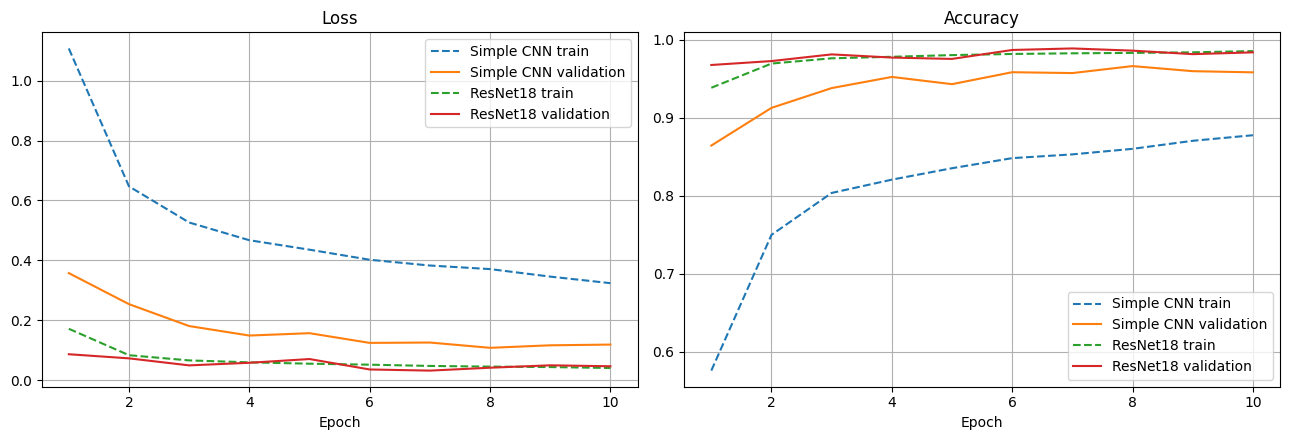

In [23]:
# --- 4.3 Learning curves ---
def plot_curves(histories):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for name, history in histories:
        axes[0].plot(history["epoch"], history["train_loss"], "--", label=f"{name} train")
        axes[0].plot(history["epoch"], history["val_loss"], label=f"{name} validation")
        axes[1].plot(history["epoch"], history["train_acc"], "--", label=f"{name} train")
        axes[1].plot(history["epoch"], history["val_acc"], label=f"{name} validation")
    axes[0].set_title("Loss")
    axes[1].set_title("Accuracy")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()

plot_curves([("Simple CNN", cnn_history), ("ResNet18", resnet_history)])

### Training observations (from the learning curves above)

| Model | What the curves show | Meaning |
| :--- | :--- | :--- |
| Simple CNN | Training accuracy is still rising at epoch 10, and validation accuracy only levels off near the end (best at epoch 8 of 10). | Slight **underfitting**: the model had not finished learning. More epochs or a larger network would likely help. |
| ResNet18 | Validation accuracy peaks around epochs 6-7. After that, training loss keeps falling while validation loss starts rising again. | The start of **overfitting**: the model begins to fit the training images more closely than it generalises. |
| Both | Validation accuracy is higher than training accuracy. | Expected: training images are augmented (and the CNN uses dropout), which makes training harder; validation images are not augmented. |

Strategies already used to help generalisation: transfer learning (ResNet18), data augmentation, dropout and batch normalisation (CNN), and keeping the weights from the best validation epoch.

**Change made (ResNet18 v2):** because ResNet18 began to overfit after its best epoch, it is retrained with two additions (lec11):
* **Learning-rate scheduling** (`ReduceLROnPlateau`): when validation loss does not improve for an epoch, the learning rate is halved. Smaller steps near the best point let the model fine-tune instead of drifting into overfitting.
* **Early stopping** (patience 3, up to 15 epochs): training stops once validation loss has not improved for 3 epochs, so no time is spent on epochs that only overfit.

Everything else (data, augmentation, optimiser, starting learning rate) stays the same, so any difference comes from this change.

In [24]:
# --- 4.4 Train ResNet18 v2: learning-rate scheduler + early stopping ---
seed_everything()
resnet_v2_model, resnet_v2_history = train_model(build_resnet18(), "resnet18_v2", epochs=15, lr=1e-4,
                                                 use_scheduler=True, patience=3)

resnet18_v2 epoch 1/15 | train loss 0.172, acc 0.939 | val loss 0.078, acc 0.970 | lr 1e-04 | 77s
resnet18_v2 epoch 2/15 | train loss 0.083, acc 0.969 | val loss 0.081, acc 0.970 | lr 1e-04 | 75s
resnet18_v2 epoch 3/15 | train loss 0.065, acc 0.976 | val loss 0.049, acc 0.983 | lr 1e-04 | 75s
resnet18_v2 epoch 4/15 | train loss 0.060, acc 0.978 | val loss 0.060, acc 0.977 | lr 1e-04 | 75s
resnet18_v2 epoch 5/15 | train loss 0.055, acc 0.980 | val loss 0.069, acc 0.975 | lr 1e-04 | 75s
resnet18_v2 epoch 6/15 | train loss 0.040, acc 0.985 | val loss 0.036, acc 0.986 | lr 5e-05 | 74s
resnet18_v2 epoch 7/15 | train loss 0.035, acc 0.987 | val loss 0.031, acc 0.988 | lr 5e-05 | 74s
resnet18_v2 epoch 8/15 | train loss 0.034, acc 0.987 | val loss 0.036, acc 0.988 | lr 5e-05 | 75s
resnet18_v2 epoch 9/15 | train loss 0.032, acc 0.988 | val loss 0.052, acc 0.981 | lr 5e-05 | 74s
resnet18_v2 epoch 10/15 | train loss 0.025, acc 0.991 | val loss 0.045, acc 0.984 | lr 3e-05 | 74s
Early stopping: val

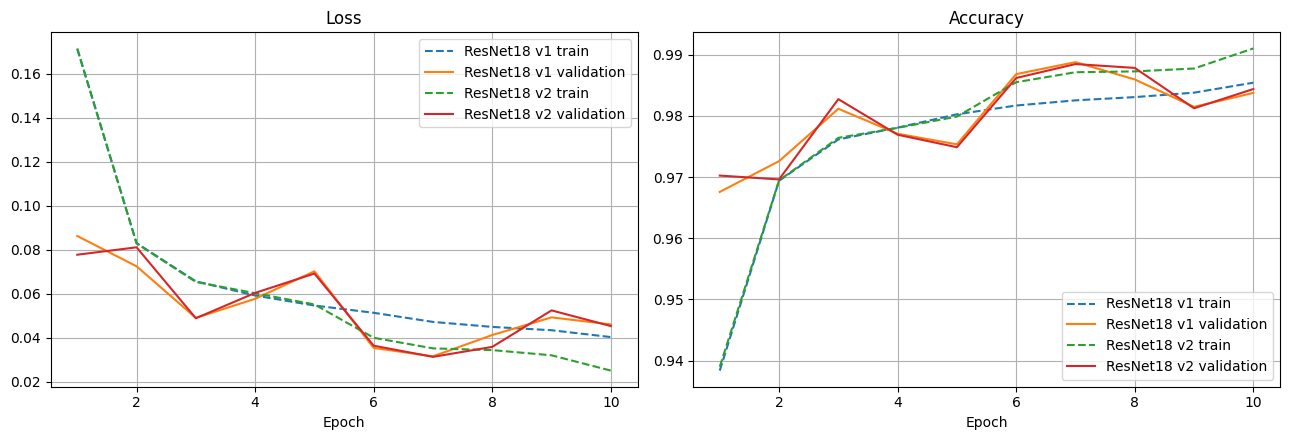

      model  epochs trained  best epoch  best val accuracy  lowest val loss
 Simple CNN              10           8             0.9661           0.1077
ResNet18 v1              10           7             0.9888           0.0315
ResNet18 v2              10           7             0.9885           0.0313


In [25]:
# --- 4.5 Compare ResNet18 before and after the change ---
plot_curves([("ResNet18 v1", resnet_history), ("ResNet18 v2", resnet_v2_history)])

summary = pd.DataFrame([
    {"model": name, "epochs trained": len(h), "best epoch": int(h.loc[h["val_acc"].idxmax(), "epoch"]),
     "best val accuracy": h["val_acc"].max(), "lowest val loss": h["val_loss"].min()}
    for name, h in [("Simple CNN", cnn_history), ("ResNet18 v1", resnet_history), ("ResNet18 v2", resnet_v2_history)]
])
print(summary.round(4).to_string(index=False))

### Result of the change

| Model | Epochs trained | Best epoch | Best validation accuracy | Lowest validation loss |
| :--- | :--- | :--- | :--- | :--- |
| Simple CNN | 10 | 8 | 96.61% | 0.1077 |
| ResNet18 v1 | 10 | 7 | **98.88%** | 0.0315 |
| ResNet18 v2 (scheduler + early stopping) | 10 (stopped early, max 15) | 7 | 98.85% | **0.0313** |

In v2, validation loss rose after epoch 5, so the scheduler halved the learning rate (0.0001 to 0.00005). The next two epochs gave its best results (validation loss 0.031, accuracy 98.85% at epoch 7). Validation loss then did not improve for 3 epochs, so early stopping ended training at epoch 10 instead of 15.

The change worked as intended in terms of training behaviour: smaller learning steps once validation loss stopped improving, the lowest validation loss of all models, and no wasted epochs once the model began to overfit. However, it did **not** clearly improve accuracy: v1 and v2 finished within 0.03 percentage points of each other in this run. In an earlier run of the same notebook, v2 was ahead (99.09% vs 98.77%), so the differences between the two versions are about the size of run-to-run randomness on the GPU. The conclusion is that ResNet18 had already reached about 98.9% with a fixed learning rate, and the scheduler and early stopping mainly make training more efficient rather than more accurate. Following the rule in 5.1, the model with the highest validation accuracy in this run (ResNet18 v1) is used as the final model.

# Task 5: Model Evaluation and Kaggle Submission

In [26]:
# --- 5.1 Choose the final model (highest validation accuracy) ---
candidates = {
    "Simple CNN": (cnn_model, cnn_history),
    "ResNet18 v1": (resnet_model, resnet_history),
    "ResNet18 v2": (resnet_v2_model, resnet_v2_history),
}
best_name = max(candidates, key=lambda name: candidates[name][1]["val_acc"].max())
best_model = candidates[best_name][0]
print("Final model:", best_name)

Final model: ResNet18 v1


In [27]:
# --- 5.2 Validation accuracy, loss, precision, recall and F1 ---
from sklearn.metrics import classification_report, confusion_matrix

val_loss, val_acc = run_epoch(best_model, val_loader, nn.CrossEntropyLoss())
val_preds = predict(best_model, val_loader)
val_true = val_split["label"].tolist()

print(f"Validation accuracy: {val_acc:.4f} | validation loss: {val_loss:.4f}")
print(f"Baseline (always predict CatEye): {(val_split['class'] == 'CatEye').mean():.4f}\n")
print(classification_report(val_true, val_preds, target_names=CLASS_NAMES, digits=3))

Validation accuracy: 0.9888 | validation loss: 0.0315
Baseline (always predict CatEye): 0.2181

              precision    recall  f1-score   support

      CatEye      0.999     0.992     0.996      2777
     CatFace      0.999     0.999     0.999      1388
    CatMouth      0.950     0.985     0.967      1388
     CatNose      0.980     0.948     0.964      1389
      DogEye      0.991     0.996     0.993      2316
     DogFace      0.995     0.998     0.997      1158
    DogMouth      0.991     0.995     0.993      1158
     DogNose      0.997     0.992     0.995      1158

    accuracy                          0.989     12732
   macro avg      0.988     0.988     0.988     12732
weighted avg      0.989     0.989     0.989     12732



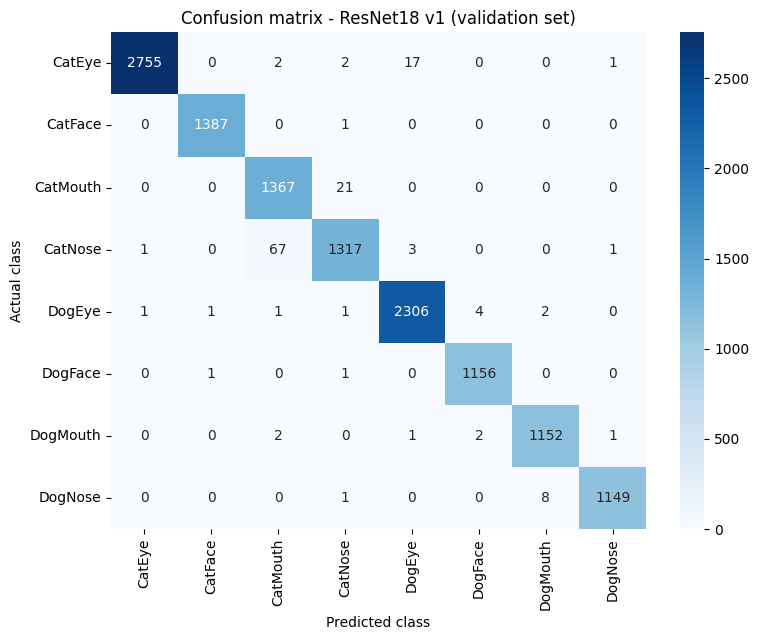

In [28]:
# --- 5.3 Confusion matrix ---
cm = confusion_matrix(val_true, val_preds)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title(f"Confusion matrix - {best_name} (validation set)")
plt.tight_layout()
plt.show()

### Evaluation results

| Metric (validation set, 12,732 images) | ResNet18 v1 (final model) |
| :--- | :--- |
| Accuracy | **98.88%** (baseline of always predicting CatEye: 21.81%) |
| Loss | 0.0315 |
| Macro-average precision / recall / F1 | 0.988 / 0.988 / 0.988 |

* **Per class:** six of the eight classes have an F1-score of 0.993 or higher. The two weakest are **CatNose** (F1 0.964, recall 0.948) and **CatMouth** (F1 0.967, precision 0.950). The high macro average shows the model works well on the smaller dog classes too, not just on the large CatEye class.
* **Confusion matrix:** the largest error is **CatNose predicted as CatMouth (67 images)**, followed by CatMouth predicted as CatNose (21). This matches Task 1: cat mouth crops usually include the nose, so the two classes overlap visually. The next error is CatEye predicted as DogEye (17), where small, dark eye crops look alike. Every other mix-up has 8 images or fewer.

In [29]:
# --- 5.4 Kaggle submission file ---
submission = make_submission(best_model)
print("Submission made with:", best_name, "|", len(submission), "rows")
print(submission.head())
print(submission["class"].value_counts())

Submission made with: ResNet18 v1 | 29443 rows
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth
class
CatEye      6275
DogEye      5589
CatMouth    3366
CatFace     3111
DogMouth    2853
DogFace     2818
CatNose     2807
DogNose     2624
Name: count, dtype: int64


### Kaggle submission

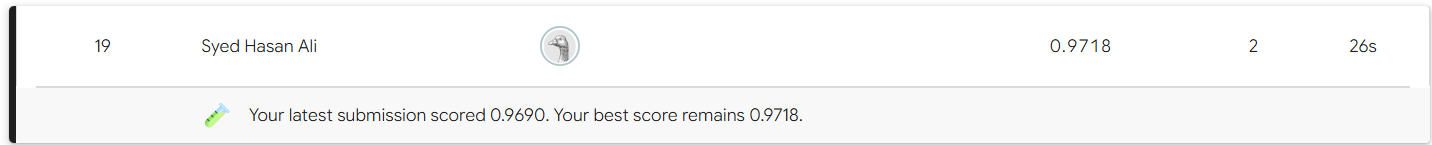

| | Accuracy |
| :--- | :--- |
| Validation set (ResNet18 v1, this run) | 98.88% |
| Kaggle public leaderboard (this run's submission) | **96.90%** |
| Best leaderboard score (earlier run of this notebook, ResNet18 v2, 99.09% validation) | 97.18% (19th place at the time of submission) |

**Validation vs leaderboard:** the leaderboard score is about 2 percentage points lower than the validation accuracy, in both runs. The validation images come from the same source as the training images, but Task 1 showed that the test crops are cut differently: only about a third of test images are square, compared with about two thirds of training images. The random crops used in training (Task 2) reduce this gap but do not remove it, so the validation set overestimates performance on the test set. The public leaderboard is also computed on only part of the test set, so the final (private) score may differ slightly. Even so, both scores are far above the 21.8% baseline and show the model generalises well to unseen images.

# Task 6: Results Analysis and Improvement Strategies

Misclassified: 143 of 12732 validation images

Most common mistakes (actual -> predicted):
class     predicted
CatNose   CatMouth     67
CatMouth  CatNose      21
CatEye    DogEye       17
DogNose   DogMouth      8
DogEye    DogFace       4
dtype: int64


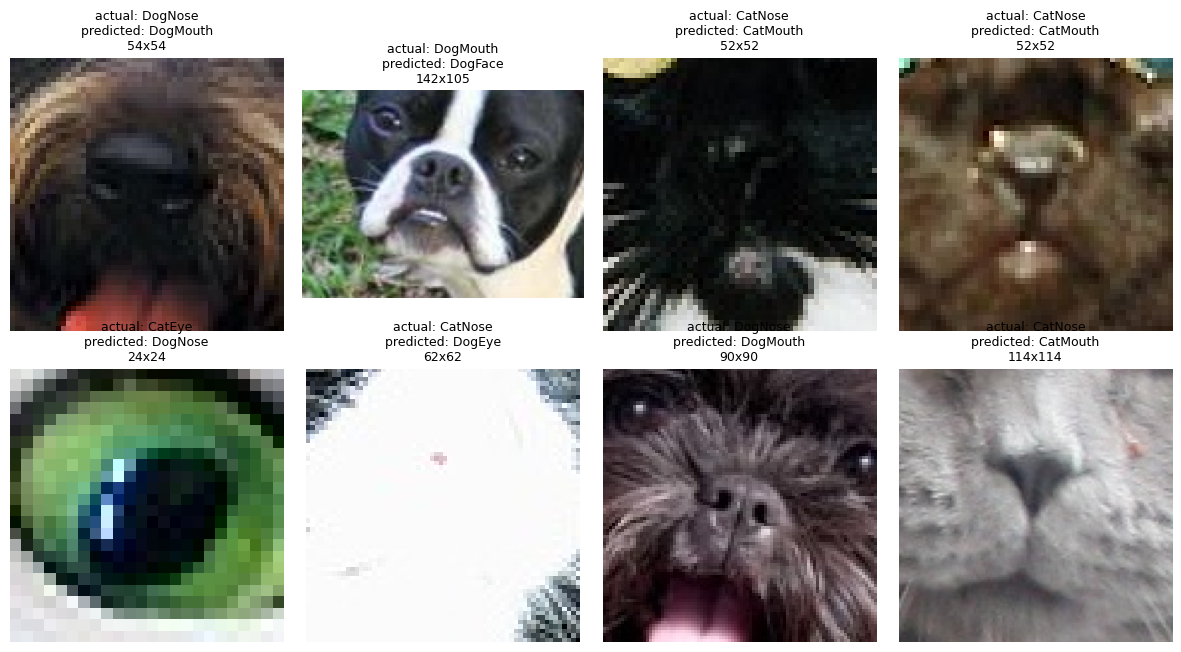

In [30]:
# --- 6.1 Misclassified validation images and the most common mistakes ---
val_results = val_split.reset_index(drop=True).copy()
val_results["predicted"] = [IDX_TO_CLASS[p] for p in val_preds]
wrong = val_results[val_results["class"] != val_results["predicted"]]
print(f"Misclassified: {len(wrong)} of {len(val_results)} validation images\n")
print("Most common mistakes (actual -> predicted):")
print(wrong.groupby(["class", "predicted"]).size().sort_values(ascending=False).head(5))

fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, (_, row) in zip(axes.flatten(), wrong.sample(min(8, len(wrong)), random_state=RANDOM_SEED).iterrows()):
    img = Image.open(os.path.join(TRAIN_IMG_DIR, row["filename"]))
    ax.imshow(img)
    ax.set_title(f"actual: {row['class']}\npredicted: {row['predicted']}\n{img.width}x{img.height}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Results analysis

**Interpreting the results.** The final model, ResNet18 v1, classifies 98.88% of the validation images correctly and scored 96.90% on the Kaggle public leaderboard (best score from an earlier run: 97.18%), against a baseline of 21.8% for always guessing the most common class. Only 143 of the 12,732 validation images are misclassified.

**Common misclassifications and difficult classes**

| Mistake (actual -> predicted) | Count | Likely reason |
| :--- | :--- | :--- |
| CatNose -> CatMouth | 67 | Cat mouth crops usually include the nose, so a close-up of a nose can look very similar to a mouth crop. |
| CatMouth -> CatNose | 21 | The same overlap in the other direction. |
| CatEye -> DogEye | 17 | Small, dark or blurry eye crops show few details that separate a cat eye from a dog eye. |

Most errors involve cat classes, and the CatNose/CatMouth pair alone accounts for 88 of the 143. Dog classes and both face classes are classified almost perfectly, because faces are larger crops with much more detail. The misclassified examples above are mostly small, dark or blurry crops where even a person would struggle to tell the part or the species.

**Reasons for the remaining errors**
* **Overlapping classes:** mouth and nose crops of the same animal share a lot of the same area.
* **Low-quality images:** about 7% of images are under 32 px on one side, so even after resizing there is little detail to learn from.
* **Different test crops:** the test images are shaped differently from the training images (Task 1), which is the most likely reason the leaderboard score is about 2 points below validation.
* **Fixed input size:** 128 x 128 keeps training fast but loses some detail in the larger face crops.

**How well each part of the pipeline worked**

| Part | Effect |
| :--- | :--- |
| Preprocessing (resize to 128 px, ImageNet normalisation) | Fast to train and matched what the pretrained ResNet18 expects. A larger size might recover detail on small features. |
| Augmentation (varied crops, flip, rotation, colour) | Reduced overfitting (validation accuracy stayed above training accuracy) and helped with the differently shaped test crops, but did not fully close the validation/leaderboard gap. |
| Model choice | Transfer learning was clearly the best choice: ResNet18 reached 98.9% (best at epoch 7), while the simple CNN trained from scratch reached 96.6%. |
| Training strategy | Keeping the weights from the best epoch protected against the later overfitting. The scheduler and early stopping in v2 gave the lowest validation loss and stopped training 5 epochs early, but did not consistently improve accuracy over v1. |

**Model versions compared**

| Model | Best validation accuracy | Kaggle public score |
| :--- | :--- | :--- |
| Simple CNN | 96.61% | not submitted |
| ResNet18 v1 (final model) | **98.88%** | **96.90%** |
| ResNet18 v2 (scheduler + early stopping) | 98.85% | not submitted in this run (97.18% in an earlier run, at 99.09% validation) |

**Realistic improvements**
* **Larger input size** (e.g. 224 px) to keep more detail, especially for small eye and nose crops.
* **Test-time augmentation:** predict each test image several times (e.g. original and flipped) and average the results.
* **Ensembling:** average the predictions of the simple CNN and ResNet18, which make different kinds of mistakes.
* **A stronger pretrained model** such as ResNet50 or EfficientNet.
* **Better validation:** k-fold cross-validation, or a validation set with test-like crop shapes, to get an estimate closer to the leaderboard score.

**Strengths and weaknesses of the final solution**
* **Strengths:** very high accuracy from a simple, standard pipeline; the same preprocessing for validation and test images with no data leakage; fixed random seeds for reproducibility; and each model trains in about 15 minutes on a GPU.
* **Weaknesses:** validation accuracy overestimates the test score; cat noses and mouths are still confused; each model was trained only once per run on one split, and the v1/v2 ranking changed between runs, so small differences between versions are partly random; and, like most deep learning models, the CNN is hard to interpret (lec6).